# NHS A&E waiting times: analysis

Data: NHS England monthly A&E Attendances and Emergency Admissions, April 2024 – September 2026 (provider level).
Run `python src/load_data.py` first to build `data/ae.duckdb`. Definitions are in [`docs/data-dictionary.md`](../docs/data-dictionary.md).

**Questions**
1. How has 4-hour performance changed, and how seasonal is it?
2. Which regions and trusts are furthest from the target?
3. Is poor 4-hour performance linked to long trolley waits (flow out of A&E into beds)?

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHARTS = ROOT / "outputs" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(ROOT / "data" / "ae.duckdb"), read_only=True)
con.execute((ROOT / "sql" / "00_measures_view.sql").read_text().replace("CREATE OR REPLACE VIEW", "CREATE OR REPLACE TEMP VIEW"))
q = lambda name: con.execute((ROOT / "sql" / name).read_text()).df()

# Palette: categorical slots 1-2 plus neutral ink for reference lines and text.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS / name, bbox_inches="tight", facecolor="white")

## 1. National trend

In [2]:
trend = q("01_national_trend.sql")
trend["month"] = pd.to_datetime(trend["month"])
trend.tail(6)

,month,attendances,pct_4h_all_types,pct_4h_type1,trolley_waits_12h,trolley_12h_per_100_adm
24,2026-04-01,2345329.0,76.9,63.8,47750.0,12.4
25,2026-05-01,2457398.0,75.7,61.9,50212.0,12.7
26,2026-06-01,2437906.0,75.0,61.2,49466.0,12.7
27,2026-07-01,2487580.0,75.4,61.7,47438.0,11.9
28,2026-08-01,2342959.0,75.0,61.1,44951.0,11.6
29,2026-09-01,2444743.0,74.4,60.6,50582.0,12.8


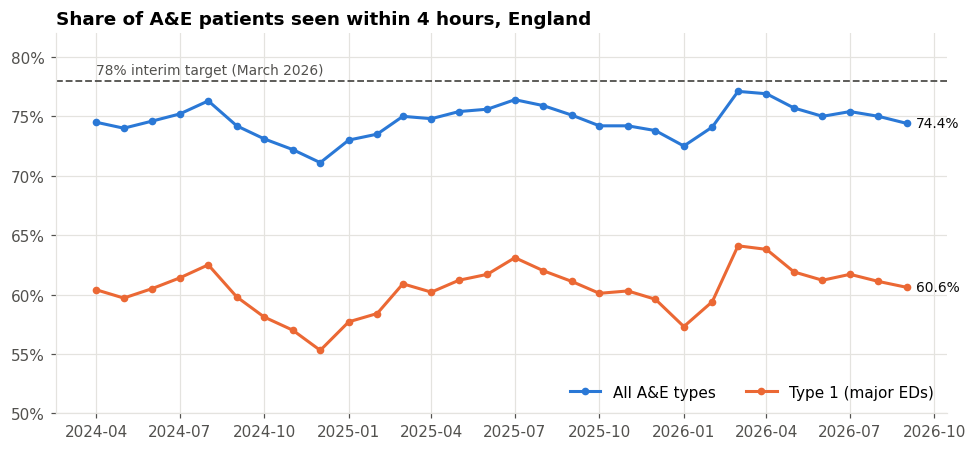

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(trend["month"], trend["pct_4h_all_types"], color=BLUE, lw=2, marker="o", ms=4, label="All A&E types")
ax.plot(trend["month"], trend["pct_4h_type1"], color=ORANGE, lw=2, marker="o", ms=4, label="Type 1 (major EDs)")
ax.axhline(78, color=MUTED, lw=1.2, ls="--")
ax.text(trend["month"].iloc[0], 78.6, "78% interim target (March 2026)", color=MUTED, fontsize=9)
for col, color in [("pct_4h_all_types", BLUE), ("pct_4h_type1", ORANGE)]:
    last = trend.iloc[-1]
    ax.annotate(f"{last[col]:.1f}%", (last["month"], last[col]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_ylim(50, 82)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Share of A&E patients seen within 4 hours, England")
ax.legend(loc="lower right", ncol=2)
save(fig, "01_national_4h_trend.png")

Performance stayed between 71% and 77% all period. The best month was March 2026 (77.1%), just short of the 78% target, and it fell back to 74.4% by September 2026. Type 1 departments, which see the sickest patients, run about 14 points below the all-types figure.

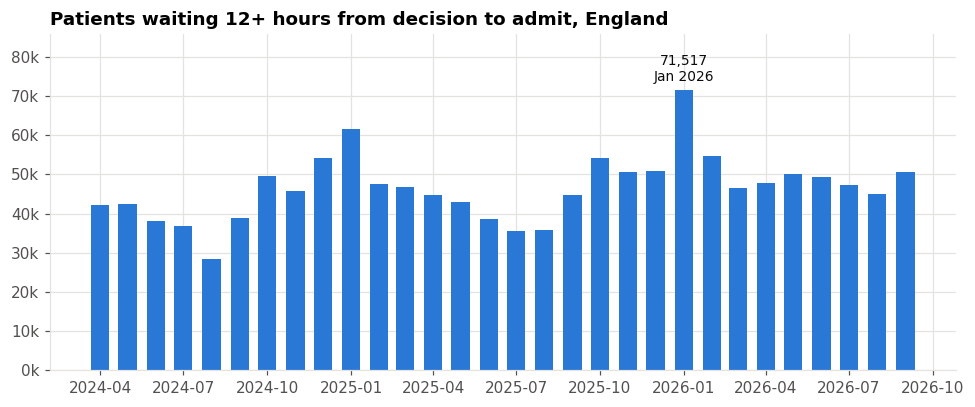

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(trend["month"], trend["trolley_waits_12h"], width=20, color=BLUE)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
peak = trend.loc[trend["trolley_waits_12h"].idxmax()]
ax.annotate(f"{peak['trolley_waits_12h']:,.0f}\n{peak['month']:%b %Y}", (peak["month"], peak["trolley_waits_12h"]),
            xytext=(0, 6), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_ylim(0, peak["trolley_waits_12h"] * 1.2)
ax.set_title("Patients waiting 12+ hours from decision to admit, England")
save(fig, "02_trolley_waits_trend.png")

## 2. Seasonality

In [5]:
season = q("02_winter_vs_summer.sql")
season

,season,season_year,months,avg_monthly_attendances,pct_4h_all_types,avg_monthly_trolley_waits_12h
0,Summer (Jun-Aug),2024,3,2259896.0,75.4,34469.0
1,Summer (Jun-Aug),2025,3,2342461.0,76.0,36686.0
2,Winter (Dec-Feb),2025,3,2217378.0,72.5,54453.0
3,Summer (Jun-Aug),2026,3,2422815.0,75.1,47285.0
4,Winter (Dec-Feb),2026,3,2254295.0,73.4,58985.0


Winter is consistently worse: 4-hour performance drops about 3 points (2.6–2.9) against the summer before, and 12-hour trolley waits rise by about 60%. Summer 2026 is worth noting: trolley waits averaged about 47,000 a month, almost 30% more than summer 2025. Pressure on beds is no longer only a winter problem.

## 3. Regions

,region,pct_4h_prior,pct_4h_latest,pct_4h_type1_latest,trolley_12h_per_100_adm_latest
6,SOUTH WEST,72.7,71.8,56.5,10.4
5,NORTH WEST,71.9,72.8,58.5,17.9
4,MIDLANDS,72.5,73.2,59.2,18.1
3,EAST OF ENGLAND,73.3,74.7,62.4,10.2
2,NORTH EAST AND YORKSHIRE,75.0,75.9,62.2,5.7
1,SOUTH EAST,76.6,76.7,63.5,11.5
0,LONDON,76.6,77.4,63.2,17.1


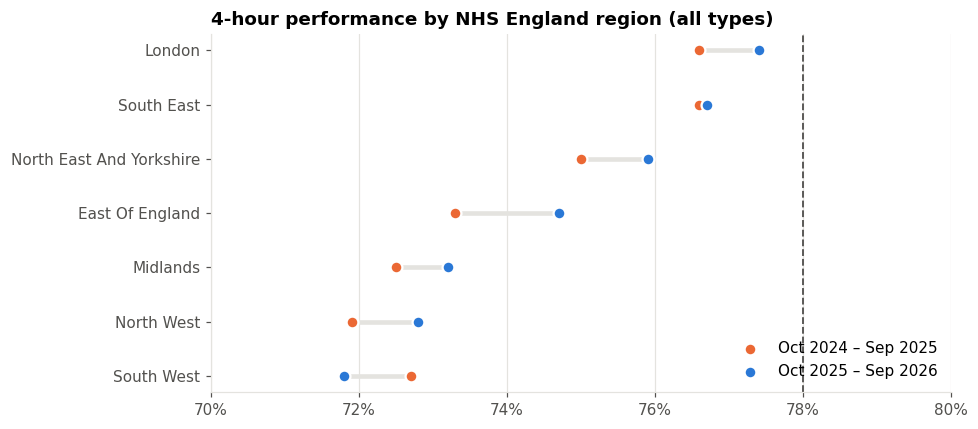

In [6]:
region = q("03_region_performance.sql").sort_values("pct_4h_latest")
fig, ax = plt.subplots(figsize=(9, 4))
y = range(len(region))
ax.hlines(y, region["pct_4h_prior"], region["pct_4h_latest"], color=GRID, lw=3)
ax.scatter(region["pct_4h_prior"], y, color=ORANGE, s=60, zorder=3, label="Oct 2024 – Sep 2025", edgecolor="white", linewidth=1.5)
ax.scatter(region["pct_4h_latest"], y, color=BLUE, s=60, zorder=3, label="Oct 2025 – Sep 2026", edgecolor="white", linewidth=1.5)
ax.set_yticks(list(y), region["region"].str.title())
ax.axvline(78, color=MUTED, lw=1.2, ls="--")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(70, 80)
ax.set_title("4-hour performance by NHS England region (all types)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "03_regions.png")
region

Six of seven regions improved slightly year on year. The South West went backwards (72.7% → 71.8%) and now has the lowest Type 1 performance (56.5%). No region reached 78% over the latest 12 months.

## 4. Trusts

In [7]:
trusts = q("04_trust_league_table.sql")
print(f"{len(trusts)} trusts with Type 1 activity in all 12 months")
print(f"Median Type 1 4-hour performance: {trusts['pct_4h_type1'].median():.1f}%")
print(f"Trusts at or above 78%: {(trusts['pct_4h_type1'] >= 78).sum()}")
print(f"Trusts below 50%: {(trusts['pct_4h_type1'] < 50).sum()}")
trusts.head(10)

120 trusts with Type 1 activity in all 12 months
Median Type 1 4-hour performance: 59.9%
Trusts at or above 78%: 6
Trusts below 50%: 17


,org_code,trust,region,type1_attendances,pct_4h_type1,trolley_12h_per_100_adm
0,RK9,UNIVERSITY HOSPITALS PLYMOUTH NHS TRUST,SOUTH WEST,106081.0,38.1,15.2
1,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,MIDLANDS,154627.0,42.8,26.4
2,RXW,THE SHREWSBURY AND TELFORD HOSPITAL NHS TRUST,MIDLANDS,134035.0,44.7,37.2
3,RVW,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,NORTH EAST AND YORKSHIRE,60393.0,46.2,1.3
4,RBL,WIRRAL UNIVERSITY TEACHING HOSPITAL NHS FOUNDA...,NORTH WEST,96863.0,46.2,33.2
5,RWA,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,NORTH EAST AND YORKSHIRE,120643.0,47.0,12.5
6,RJE,UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST,MIDLANDS,188037.0,47.0,19.5
7,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,SOUTH WEST,84989.0,47.2,23.5
8,RAX,KINGSTON AND RICHMOND NHS FOUNDATION TRUST,LONDON,85794.0,47.3,17.5
9,RFS,CHESTERFIELD ROYAL HOSPITAL NHS FOUNDATION TRUST,MIDLANDS,84132.0,47.8,13.5


## 5. Is the bottleneck flow out of A&E?

,trolley_wait_quartile,trusts,trolley_12h_per_100_adm_range,pct_4h_type1,median_trust_pct_4h_type1
0,1,30,0.0 - 3.5,65.4,64.1
1,2,30,3.6 - 12.3,61.8,61.5
2,3,30,12.3 - 19.8,58.2,56.0
3,4,30,19.9 - 61.5,58.8,56.9


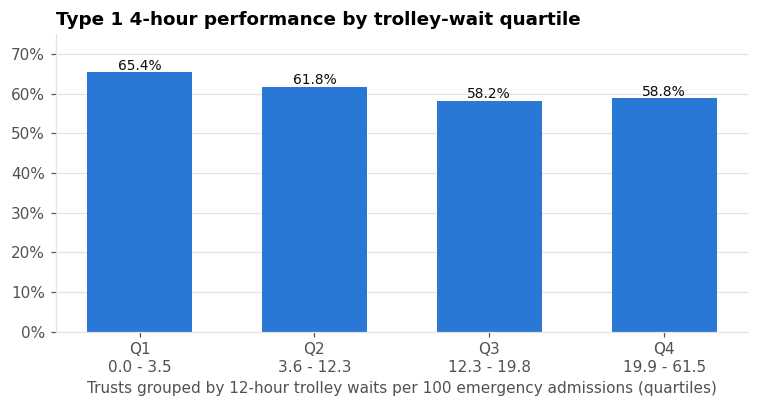

In [8]:
quart = q("05_bottleneck_quartiles.sql")
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = [f"Q{r.trolley_wait_quartile}\n{r.trolley_12h_per_100_adm_range}" for r in quart.itertuples()]
bars = ax.bar(labels, quart["pct_4h_type1"], color=BLUE, width=0.6)
for b, v in zip(bars, quart["pct_4h_type1"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}%", ha="center", color=INK, fontsize=9)
ax.set_ylim(0, 75)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Trusts grouped by 12-hour trolley waits per 100 emergency admissions (quartiles)")
ax.set_title("Type 1 4-hour performance by trolley-wait quartile")
ax.grid(axis="x", visible=False)
save(fig, "04_quartiles.png")
quart

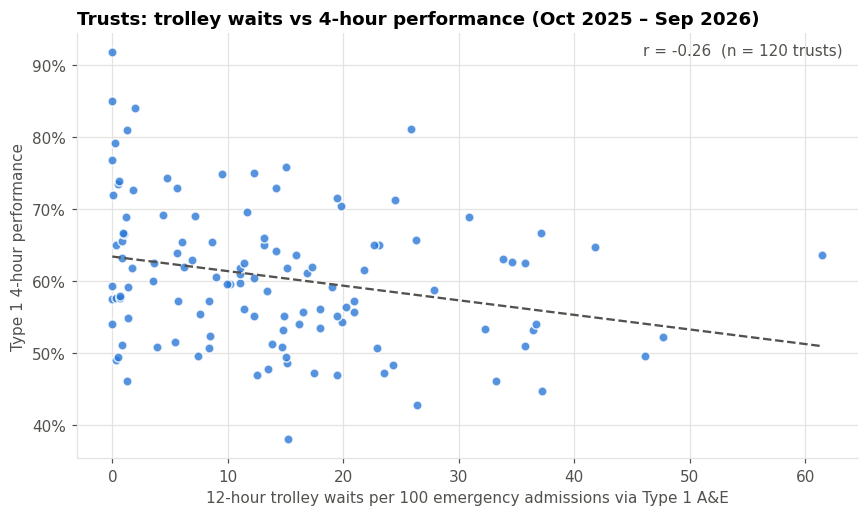

In [9]:
import numpy as np
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(trusts["trolley_12h_per_100_adm"], trusts["pct_4h_type1"], color=BLUE, s=36, alpha=0.8, edgecolor="white", linewidth=1)
slope, intercept = np.polyfit(trusts["trolley_12h_per_100_adm"], trusts["pct_4h_type1"], 1)
xs = np.linspace(0, trusts["trolley_12h_per_100_adm"].max(), 50)
ax.plot(xs, slope * xs + intercept, color=MUTED, lw=1.5, ls="--")
r = trusts[["trolley_12h_per_100_adm", "pct_4h_type1"]].corr().iloc[0, 1]
ax.text(0.98, 0.95, f"r = {r:.2f}  (n = {len(trusts)} trusts)", transform=ax.transAxes, ha="right", color=MUTED)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("12-hour trolley waits per 100 emergency admissions via Type 1 A&E")
ax.set_ylabel("Type 1 4-hour performance")
ax.set_title("Trusts: trolley waits vs 4-hour performance (Oct 2025 – Sep 2026)")
save(fig, "05_trust_scatter.png")

In [10]:
low_recorders = trusts[trusts["trolley_12h_per_100_adm"] < 1]
rest = trusts[trusts["trolley_12h_per_100_adm"] >= 1]
print(f"Trusts reporting fewer than 1 trolley wait per 100 admissions: {len(low_recorders)}")
print(f"Correlation excluding them: {rest[['trolley_12h_per_100_adm','pct_4h_type1']].corr().iloc[0,1]:.2f}")
low_recorders[["trust", "pct_4h_type1", "trolley_12h_per_100_adm"]].head(10)

Trusts reporting fewer than 1 trolley wait per 100 admissions: 20
Correlation excluding them: -0.20


,trust,pct_4h_type1,trolley_12h_per_100_adm
12,SHEFFIELD TEACHING HOSPITALS NHS FOUNDATION TRUST,49.0,0.3
14,HAMPSHIRE HOSPITALS NHS FOUNDATION TRUST,49.5,0.5
22,SOUTH TEES HOSPITALS NHS FOUNDATION TRUST,51.1,0.8
31,MILTON KEYNES UNIVERSITY HOSPITAL NHS FOUNDATI...,54.0,0.0
48,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,57.5,0.0
49,GATESHEAD HEALTH NHS FOUNDATION TRUST,57.7,0.3
50,THE NEWCASTLE UPON TYNE HOSPITALS NHS FOUNDATI...,57.7,0.7
51,COUNTY DURHAM AND DARLINGTON NHS FOUNDATION TRUST,57.9,0.7
56,IMPERIAL COLLEGE HEALTHCARE NHS TRUST,59.3,0.0
77,BEDFORDSHIRE HOSPITALS NHS FOUNDATION TRUST,63.2,0.8


**Reading this carefully:**

- Trusts in the lowest trolley-wait quartile perform about 6–7 points better on the 4-hour target than the rest. So flow out of A&E matters.
- But the link is weak (r ≈ −0.26, and −0.20 if the 20 near-zero reporters are left out). Among the 40 trusts with 10–20 trolley waits per 100 admissions, Type 1 performance ranges from 38% to 76%.
- So most of the variation between trusts is **not** explained by trolley waits. What happens inside the department (time to assessment and decision, staffing, use of same-day emergency care) is likely to matter as much, but this dataset can't show it.
- 20 trusts report almost no 12-hour trolley waits. Some are children's trusts, where this is plausible; for others it may reflect how waits are recorded. This should be checked before drawing trust-level conclusions.

The findings and recommendations are written up in [`docs/findings-and-recommendations.md`](../docs/findings-and-recommendations.md).